⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng...
🚀 Running Final Strategy...

FINAL STRATEGY - MA30 + RSI + KC Triple
     Final Equity: 11933.1899
     Total Return: 0.1933
    CAGR (approx): 0.1674
     Max Drawdown: -0.1241
           Sharpe: 0.9703
           Trades: 165
          Winrate: 0.3758
    Avg PnL/Trade: 11.7163
    Profit Factor: 1.1894


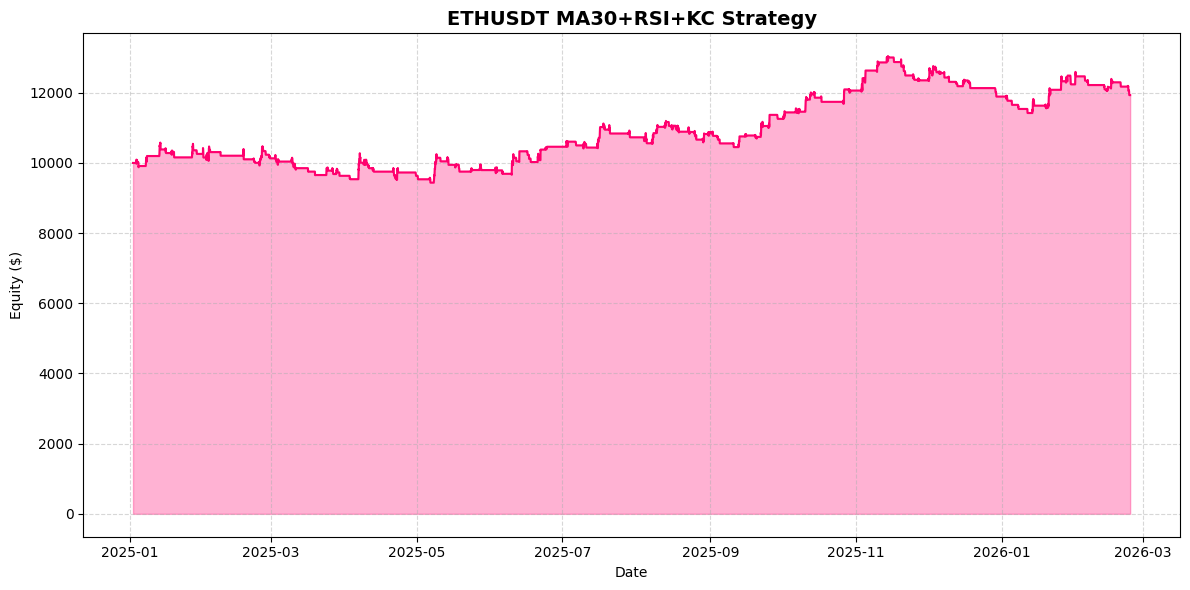


📊 Trades: 165
            Exit Time   Type        Entry         Exit         PnL       Reason       Balance
0 2025-01-04 09:00:00   LONG  3584.280000  3589.550000   12.910037    Time Exit  10012.910037
1 2025-01-04 16:00:00   LONG  3653.679171  3619.664704 -100.129100    Stop Loss   9912.780937
2 2025-01-08 03:00:00  SHORT  3462.650000  3344.209790  284.371432  Take Profit  10197.152368
3 2025-01-13 11:00:00  SHORT  3177.852743  3061.782114  293.935616  Take Profit  10491.087984
4 2025-01-13 20:00:00  SHORT  3046.970000  3094.811241 -104.910880    Stop Loss  10386.177104
5 2025-01-16 02:00:00   LONG  3434.990000  3383.260149 -103.861771    Stop Loss  10282.315333
6 2025-01-18 23:00:00  SHORT  3295.939956  3307.710000  -20.523768    Time Exit  10261.791565
7 2025-01-19 13:00:00  SHORT  3180.601450  3240.477357 -102.617916    Stop Loss  10159.173649
8 2025-01-27 06:00:00  SHORT  3214.130000  3114.893806  306.787039  Take Profit  10465.960688
9 2025-01-27 12:00:00  SHORT  3070.800000  31

In [2]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. HÀM TẢI DỮ LIỆU ---
def str_to_millis(date_str):
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol, interval, start_str, end_str):
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    general_url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")
    
    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            response = requests.get(general_url, params=params, timeout=10)
            if response.status_code != 200:
                print("Error:", response.status_code, response.text)
                break
            data = response.json()
            if not data: break
            all_klines.extend(data)
            last_ts = data[-1][0]
            start_time = last_ts + 1
            time.sleep(0.05) 
        except Exception as e:
            print(f"Lỗi: {e}")
            break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# --- 2. HÀM TÍNH CHỈ BÁO ---
def calculate_indicators(df):
    data = df.copy()
    
    # Typical Price = (High + Low + Close) / 3
    data['Typical_Price'] = (data['High'] + data['Low'] + data['Close']) / 3
    
    # True Range
    data['prev_close'] = data['Close'].shift(1)
    data['h_l'] = data['High'] - data['Low']
    data['h_pc'] = (data['High'] - data['prev_close']).abs()
    data['l_pc'] = (data['Low'] - data['prev_close']).abs()
    data['TR'] = data[['h_l', 'h_pc', 'l_pc']].max(axis=1)
    
    # ATR function
    def calc_atr(series_tr, period):
        return series_tr.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    # ATR các period
    data['ATR_20'] = calc_atr(data['TR'], 20)
    data['ATR_25'] = calc_atr(data['TR'], 25)
    
    # MA(30) on Typical Price
    data['MA_30_Typical'] = data['Typical_Price'].rolling(window=30).mean()
    
    # RSI(40) on Close
    def calc_rsi(series, period):
        delta = series.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
        rs = gain / loss
        rsi = 100 - (100 / (1 + rs))
        return rsi
    
    data['RSI_40'] = calc_rsi(data['Close'], 40)
    
    # Keltner Channel (20, dev=1.9)
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    data['KC_Upper_20'] = data['EMA_20'] + (1.9 * data['ATR_20'])
    data['KC_Lower_20'] = data['EMA_20'] - (1.9 * data['ATR_20'])
    
    # Highest/Lowest Close trong 10 nến
    data['Highest_Close_10'] = data['Close'].rolling(window=10).max()
    data['Lowest_Close_10'] = data['Close'].rolling(window=10).min()
    
    data.dropna(inplace=True)
    return data

# --- 3. BACKTESTER ---
class MA30RSIKCBacktester:
    def __init__(self, df, initial_balance=10000):
        self.df = df
        self.initial_balance = initial_balance
        self.balance = initial_balance
        self.equity_curve = [] 
        self.trades = []
        self.position = None 
        self.entry_price = 0
        self.sl = 0
        self.tp = 0
        self.entry_bar_idx = 0
        self.qty = 0
        self.pending_order = None 
        
        # Strategy Parameters
        self.risk_pct = 0.01  # 1%
        self.price_entry_mult = 2.4  # Entry buffer
        self.sl_coef = 1.5  # SL = 1.5 * ATR(20)
        self.tp_coef = 4.4  # TP = 4.4 * ATR(25)
        self.exit_after_bars = 16
        self.pending_expiration = 3
        
    def run(self):
        indices = self.df.index
        
        for i in range(len(self.df)):
            current_bar = self.df.iloc[i]
            idx = indices[i]
            
            # A. QUẢN LÝ LỆNH ĐANG MỞ
            if self.position is not None:
                bars_held = i - self.entry_bar_idx
                if bars_held >= self.exit_after_bars:
                    self.close_position(current_bar['Close'], idx, "Time Exit")
                    self.append_equity(idx)
                    continue
                
                if self.position == 'LONG':
                    if current_bar['Low'] <= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if current_bar['High'] >= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
                
                elif self.position == 'SHORT':
                    if current_bar['High'] >= self.sl:
                        self.close_position(self.sl, idx, "Stop Loss")
                        self.append_equity(idx)
                        continue
                    if current_bar['Low'] <= self.tp:
                        self.close_position(self.tp, idx, "Take Profit")
                        self.append_equity(idx)
                        continue
            
            # B. QUẢN LÝ PENDING ORDER
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order['expire_idx']:
                    self.pending_order = None
                else:
                    p_price = self.pending_order['price']
                    
                    if self.pending_order['type'] == 'BUY_STOP' and current_bar['High'] >= p_price:
                        self.open_position('LONG', max(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
                    
                    elif self.pending_order['type'] == 'SELL_STOP' and current_bar['Low'] <= p_price:
                        self.open_position('SHORT', min(p_price, current_bar['Open']), i, 
                                         self.pending_order['sl_dist'], 
                                         self.pending_order['tp_dist'])
                        self.pending_order = None
            
            # C. TÍN HIỆU VÀO LỆNH
            if self.position is None and self.pending_order is None:
                if i < 4:
                    self.append_equity(idx)
                    continue
                
                # Current Open
                open_current = current_bar['Open']
                
                # MA Trend Filter (shift=1)
                close_shift1 = self.df.iloc[i-1]['Close']
                ma_typical_shift1 = self.df.iloc[i-1]['MA_30_Typical']
                
                # RSI Momentum (shift=4 vs shift=3)
                rsi_shift4 = self.df.iloc[i-4]['RSI_40']
                rsi_shift3 = self.df.iloc[i-3]['RSI_40']
                
                # KC Breakout Filter (shift=1)
                kc_upper_shift1 = self.df.iloc[i-1]['KC_Upper_20']
                kc_lower_shift1 = self.df.iloc[i-1]['KC_Lower_20']
                
                # LONG SIGNAL (3 conditions)
                long_signal = (
                    close_shift1 > ma_typical_shift1 and   # Above MA(30) on Typical
                    rsi_shift4 < rsi_shift3 and            # RSI rising
                    open_current > kc_upper_shift1         # Open above KC upper
                )
                
                # SHORT SIGNAL (3 conditions)
                short_signal = (
                    close_shift1 < ma_typical_shift1 and   # Below MA(30) on Typical
                    rsi_shift4 > rsi_shift3 and            # RSI falling
                    open_current < kc_lower_shift1         # Open below KC lower
                )
                
                if not long_signal and not short_signal:
                    self.append_equity(idx)
                    continue
                
                # Entry parameters (shift=3)
                highest_close_shift3 = self.df.iloc[i-3]['Highest_Close_10']
                lowest_close_shift3 = self.df.iloc[i-3]['Lowest_Close_10']
                atr_20_shift3 = self.df.iloc[i-3]['ATR_20']
                
                # SL/TP parameters (shift=1)
                atr_20_shift1 = self.df.iloc[i-1]['ATR_20']
                atr_25_shift1 = self.df.iloc[i-1]['ATR_25']
                
                # CREATE PENDING ORDERS
                if long_signal:
                    entry_price = highest_close_shift3 + (self.price_entry_mult * atr_20_shift3)
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_25_shift1
                    
                    self.pending_order = {
                        'type': 'BUY_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
                
                elif short_signal and not long_signal:
                    entry_price = lowest_close_shift3 - (self.price_entry_mult * atr_20_shift3)
                    sl_distance = self.sl_coef * atr_20_shift1
                    tp_distance = self.tp_coef * atr_25_shift1
                    
                    self.pending_order = {
                        'type': 'SELL_STOP',
                        'price': entry_price,
                        'sl_dist': sl_distance,
                        'tp_dist': tp_distance,
                        'expire_idx': i + self.pending_expiration
                    }
            
            # D. APPEND EQUITY
            self.append_equity(idx)
    
    def append_equity(self, idx):
        mark_to_market = self.balance
        if self.position == 'LONG':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (current_price - self.entry_price) * self.qty
            mark_to_market += unrealized
        elif self.position == 'SHORT':
            current_price = self.df.loc[idx, 'Close']
            unrealized = (self.entry_price - current_price) * self.qty
            mark_to_market += unrealized
        
        self.equity_curve.append({'time': idx, 'equity': mark_to_market})
    
    def open_position(self, pos_type, price, bar_idx, sl_dist, tp_dist):
        self.position = pos_type
        self.entry_price = price
        self.entry_bar_idx = bar_idx
        
        if pos_type == 'LONG':
            self.sl = price - sl_dist
            self.tp = price + tp_dist
        else:
            self.sl = price + sl_dist
            self.tp = price - tp_dist
        
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(price - self.sl)
        self.qty = risk_amount / sl_distance if sl_distance > 0 else 0
    
    def close_position(self, price, time_idx, reason):
        if self.position == 'LONG':
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty
        
        self.balance += pnl
        
        self.trades.append({
            'Exit Time': time_idx,
            'Type': self.position,
            'Entry': self.entry_price,
            'Exit': price,
            'PnL': pnl,
            'Reason': reason,
            'Balance': self.balance
        })
        
        self.position = None
        self.qty = 0

# --- 4. METRICS ---
def calculate_metrics(trades_df, equity_data, initial_balance):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index('time', inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep='last')]
    
    final_equity = eq_df['equity'].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    
    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25
    cagr = ((final_equity / initial_balance) ** (1/years)) - 1 if years > 0 else 0
    
    running_max = eq_df['equity'].cummax()
    drawdown = (eq_df['equity'] - running_max) / running_max
    max_dd = drawdown.min()
    
    eq_df['returns'] = eq_df['equity'].pct_change()
    mean_ret = eq_df['returns'].mean()
    std_ret = eq_df['returns'].std()
    bars_per_year = len(eq_df) / years if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0
    
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df['PnL'] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0
    avg_pnl = trades_df['PnL'].mean() if total_trades > 0 else 0
    
    gross_profit = trades_df[trades_df['PnL'] > 0]['PnL'].sum()
    gross_loss = abs(trades_df[trades_df['PnL'] < 0]['PnL'].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0

    return {
        'Final Equity': final_equity,
        'Total Return': total_return,
        'CAGR (approx)': cagr,
        'Max Drawdown': max_dd,
        'Sharpe': sharpe,
        'Trades': total_trades,
        'Winrate': win_rate,
        'Avg PnL/Trade': avg_pnl,
        'Profit Factor': profit_factor,
        'equity_df': eq_df
    }

def print_report_and_plot(metrics, symbol):
    print("\n" + "="*60)
    print("FINAL STRATEGY - MA30 + RSI + KC Triple")
    print("="*60)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("="*60)

    eq_df = metrics['equity_df']
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df['equity'], linewidth=1.5, color='#FF006E')
    plt.fill_between(eq_df.index, eq_df['equity'], alpha=0.3, color='#FF006E')
    
    plt.title(f"{symbol} MA30+RSI+KC Strategy", fontsize=14, fontweight='bold')
    plt.xlabel('Date')
    plt.ylabel('Equity ($)')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2025"
    end_date = "23/02/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 200:
        print("✅ Dữ liệu sẵn sàng...")
        df_calc = calculate_indicators(df_raw)
        
        print("🚀 Running Final Strategy...")
        bt = MA30RSIKCBacktester(df_calc, initial_balance=10000)
        bt.run()
        
        trades_df = pd.DataFrame(bt.trades)
        
        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)
            
            print("\n📊 Trades:", len(trades_df))
            print(trades_df.head(10).to_string())
        else:
            print("⚠️ No trades.")
    else:
        print("❌ Not enough data.")

⏳ Đang tải dữ liệu ETHUSDT khung 1h...
✅ Dữ liệu sẵn sàng...
🚀 Running Combo A backtest...

COMBO A - MA30 + RSI + KC + MA SLOPE + ATR20/ATR50 + FEES + SLIPPAGE
     Final Equity: 11539.3238
     Total Return: 0.1539
    CAGR (approx): 0.1340
     Max Drawdown: -0.1018
           Sharpe: 0.9165
           Trades: 117
          Winrate: 0.4017
    Avg PnL/Trade: 13.1566
    Profit Factor: 1.1964
💡 Estimated R:R: 1:1.78


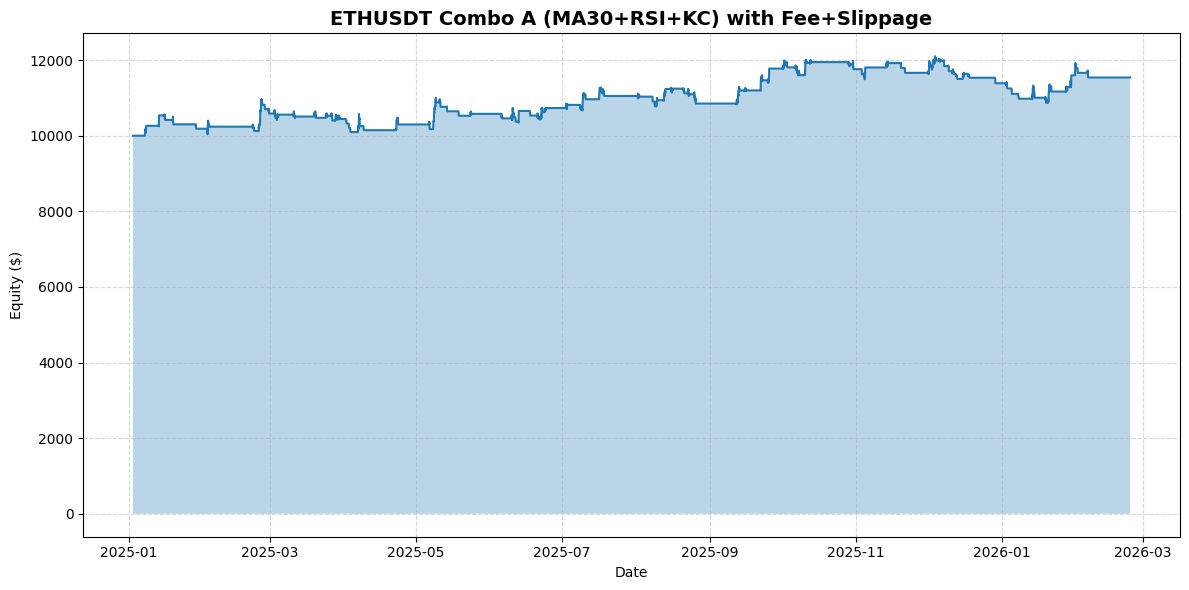


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit       Qty   PnL_gross  EntryFee   ExitFee   TotalFee     PnL_net       Reason       Balance
0 2025-01-08 06:00:00  SHORT  3456.686772  3313.974993  1.928027  275.152218  6.664587  6.389435  13.054021  262.098197  Take Profit  10262.098197
1 2025-01-13 14:00:00  SHORT  3055.927140  2928.934698  2.280653  289.625751  6.969511  6.679885  13.649396  275.976355  Take Profit  10538.074551
2 2025-01-16 02:00:00   LONG  3436.363996  3383.957218  2.037136 -106.759738  7.000341  6.893581  13.893922 -120.653660    Stop Loss  10417.420892
3 2025-01-19 13:00:00  SHORT  3202.849435  3263.377887  1.739835 -105.309530  5.572430  5.677740  11.250170 -116.559699    Stop Loss  10300.861192
4 2025-01-29 04:00:00  SHORT  3082.916340  3137.702332  1.901981 -104.201944  5.863650  5.967852  11.831502 -116.033445    Stop Loss  10184.827747
5 2025-02-02 20:00:00  SHORT  2927.188656  2984.626626  1.791805 -102.917637  5.244951  5

In [8]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================================================
# 1) FETCH BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    api_url = "api/v3/klines"
    url = base_url + api_url

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Đang tải dữ liệu {symbol} khung {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Error:", r.status_code, r.text)
                break

            data = r.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)

        except Exception as e:
            print("Fetch error:", e)
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # Typical Price = (H + L + C)/3
    data["Typical_Price"] = (data["High"] + data["Low"] + data["Close"]) / 3.0

    # True Range
    prev_close = data["Close"].shift(1)
    tr = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs()
    ], axis=1).max(axis=1)
    data["TR"] = tr

    # Wilder ATR
    def calc_atr(tr_series: pd.Series, period: int) -> pd.Series:
        return tr_series.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_25"] = calc_atr(data["TR"], 25)
    data["ATR_50"] = calc_atr(data["TR"], 50)

    # MA(30) on Typical Price
    data["MA_30_Typical"] = data["Typical_Price"].rolling(window=30).mean()

    # RSI(40) on Close
    def calc_rsi(series: pd.Series, period: int) -> pd.Series:
        delta = series.diff()
        gain = delta.where(delta > 0, 0.0).rolling(window=period).mean()
        loss = (-delta.where(delta < 0, 0.0)).rolling(window=period).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    data["RSI_40"] = calc_rsi(data["Close"], 40)

    # Keltner Channel (20, dev=1.9)
    ema20 = data["Close"].ewm(span=20, adjust=False).mean()
    data["EMA_20"] = ema20
    data["KC_Upper_20"] = ema20 + 1.9 * data["ATR_20"]
    data["KC_Lower_20"] = ema20 - 1.9 * data["ATR_20"]

    # Highest / Lowest close
    data["Highest_Close_10"] = data["Close"].rolling(window=10).max()
    data["Lowest_Close_10"] = data["Close"].rolling(window=10).min()

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER (Combo A: fee + slippage + ATR20/ATR50 + MA slope + lower entry buffer)
# =========================================================
class MA30RSIKCBacktesterComboA:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position = None  # "LONG"/"SHORT"/None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.entry_bar_idx = 0
        self.qty = 0.0

        self.pending_order = None
        self._last_entry_fee = 0.0

        # ---- Strategy Params (Combo A) ----
        self.risk_pct = 0.01
        self.price_entry_mult = 1.8         # giảm từ 2.4 -> 1.8
        self.sl_coef = 1.5
        self.tp_coef = 4.4
        self.exit_after_bars = 16
        self.pending_expiration = 3

        # ---- New filters (Combo A) ----
        self.vol_ratio_min = 1.03           # ATR20 / ATR50 > 1.03
        self.ma_slope_lookback = 3          # MA30[i-1] > MA30[i-4] cho long

        # ---- Fee + Slippage (Combo A) ----
        self.fee_rate = 0.001               # spot taker ~0.1%/side
        self.slippage_bps_entry = 4.0       # stop-entry thường trượt nhiều hơn
        self.slippage_bps_exit = 2.0        # exit giả định 2 bps

    @staticmethod
    def _bps_to_mult(bps: float) -> float:
        return bps / 10000.0

    def apply_entry_slippage(self, raw_price: float, pos_type: str) -> float:
        slip = self._bps_to_mult(self.slippage_bps_entry)
        if pos_type == "LONG":
            return raw_price * (1 + slip)
        return raw_price * (1 - slip)

    def apply_exit_slippage(self, raw_price: float, pos_type: str) -> float:
        slip = self._bps_to_mult(self.slippage_bps_exit)
        # thoát lệnh theo hướng bất lợi
        if pos_type == "LONG":
            return raw_price * (1 - slip)
        return raw_price * (1 + slip)

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            bar = self.df.iloc[i]
            t = idxs[i]

            # ---------------------------------
            # A) Manage open position
            # ---------------------------------
            if self.position is not None:
                held = i - self.entry_bar_idx

                # Time exit
                if held >= self.exit_after_bars:
                    exit_px = self.apply_exit_slippage(bar["Close"], self.position)
                    self.close_position(exit_px, t, "Time Exit")
                    self.append_equity(t)
                    continue

                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        exit_px = self.apply_exit_slippage(self.sl, "LONG")
                        self.close_position(exit_px, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["High"] >= self.tp:
                        exit_px = self.apply_exit_slippage(self.tp, "LONG")
                        self.close_position(exit_px, t, "Take Profit")
                        self.append_equity(t)
                        continue

                elif self.position == "SHORT":
                    if bar["High"] >= self.sl:
                        exit_px = self.apply_exit_slippage(self.sl, "SHORT")
                        self.close_position(exit_px, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["Low"] <= self.tp:
                        exit_px = self.apply_exit_slippage(self.tp, "SHORT")
                        self.close_position(exit_px, t, "Take Profit")
                        self.append_equity(t)
                        continue

            # ---------------------------------
            # B) Manage pending order
            # ---------------------------------
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p = self.pending_order["price"]

                    if self.pending_order["type"] == "BUY_STOP" and bar["High"] >= p:
                        fill = max(p, bar["Open"])
                        fill = self.apply_entry_slippage(fill, "LONG")
                        self.open_position(
                            "LONG", fill, i,
                            self.pending_order["sl_dist"],
                            self.pending_order["tp_dist"]
                        )
                        self.pending_order = None

                    elif self.pending_order["type"] == "SELL_STOP" and bar["Low"] <= p:
                        fill = min(p, bar["Open"])
                        fill = self.apply_entry_slippage(fill, "SHORT")
                        self.open_position(
                            "SHORT", fill, i,
                            self.pending_order["sl_dist"],
                            self.pending_order["tp_dist"]
                        )
                        self.pending_order = None

            # ---------------------------------
            # C) Signal -> place pending
            # ---------------------------------
            if self.position is None and self.pending_order is None:
                # cần đủ bar cho shift4
                if i < 4:
                    self.append_equity(t)
                    continue

                open_0 = bar["Open"]

                # --- Trend Filter (shift=1) + MA slope (Combo A)
                close_1 = self.df.iloc[i-1]["Close"]
                ma_1 = self.df.iloc[i-1]["MA_30_Typical"]
                ma_slope_ref = self.df.iloc[i-1-self.ma_slope_lookback]["MA_30_Typical"]

                ma_up = ma_1 > ma_slope_ref
                ma_dn = ma_1 < ma_slope_ref

                # --- RSI Momentum (giữ nguyên logic gốc)
                rsi_4 = self.df.iloc[i-4]["RSI_40"]
                rsi_3 = self.df.iloc[i-3]["RSI_40"]

                # --- KC Breakout Filter (shift=1)
                kc_up_1 = self.df.iloc[i-1]["KC_Upper_20"]
                kc_lo_1 = self.df.iloc[i-1]["KC_Lower_20"]

                # --- Volatility regime filter (Combo A)
                atr20_1 = self.df.iloc[i-1]["ATR_20"]
                atr50_1 = self.df.iloc[i-1]["ATR_50"]
                vol_ratio = (atr20_1 / atr50_1) if (atr50_1 > 0) else 0.0
                vol_ok = vol_ratio > self.vol_ratio_min

                long_signal = (
                    vol_ok and
                    (close_1 > ma_1) and
                    ma_up and
                    (rsi_4 < rsi_3) and
                    (open_0 > kc_up_1)
                )

                short_signal = (
                    vol_ok and
                    (close_1 < ma_1) and
                    ma_dn and
                    (rsi_4 > rsi_3) and
                    (open_0 < kc_lo_1)
                )

                if not long_signal and not short_signal:
                    self.append_equity(t)
                    continue

                # Entry params (shift=3)
                highest_close_3 = self.df.iloc[i-3]["Highest_Close_10"]
                lowest_close_3 = self.df.iloc[i-3]["Lowest_Close_10"]
                atr20_3 = self.df.iloc[i-3]["ATR_20"]

                # SL/TP params (shift=1)
                atr20_1 = self.df.iloc[i-1]["ATR_20"]
                atr25_1 = self.df.iloc[i-1]["ATR_25"]
                sl_dist = self.sl_coef * atr20_1
                tp_dist = self.tp_coef * atr25_1

                if long_signal:
                    entry_price = highest_close_3 + self.price_entry_mult * atr20_3
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry_price),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration,
                        "meta_vol_ratio": float(vol_ratio)
                    }

                elif short_signal:
                    entry_price = lowest_close_3 - self.price_entry_mult * atr20_3
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry_price),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration,
                        "meta_vol_ratio": float(vol_ratio)
                    }

            # ---------------------------------
            # D) Append equity
            # ---------------------------------
            self.append_equity(t)

    def append_equity(self, t):
        mtm = self.balance
        close_px = self.df.loc[t, "Close"]

        if self.position == "LONG":
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty

        self.equity_curve.append({"time": t, "equity": mtm})

    def open_position(self, pos_type: str, price: float, bar_idx: int, sl_dist: float, tp_dist: float):
        self.position = pos_type
        self.entry_price = float(price)
        self.entry_bar_idx = int(bar_idx)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Risk-based sizing
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        self.qty = float((risk_amount / sl_distance) if sl_distance > 0 else 0.0)

        # Entry fee
        entry_notional = self.entry_price * self.qty
        entry_fee = self.fee_rate * entry_notional
        self.balance -= entry_fee
        self._last_entry_fee = float(entry_fee)

    def close_position(self, price: float, t, reason: str):
        price = float(price)

        if self.position == "LONG":
            pnl_gross = (price - self.entry_price) * self.qty
        else:
            pnl_gross = (self.entry_price - price) * self.qty

        exit_fee = self.fee_rate * (price * self.qty)

        # entry fee đã trừ lúc vào
        pnl_net_after_exit = pnl_gross - exit_fee
        self.balance += pnl_net_after_exit

        self.trades.append({
            "Exit Time": t,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "PnL_gross": pnl_gross,
            "EntryFee": self._last_entry_fee,
            "ExitFee": exit_fee,
            "TotalFee": self._last_entry_fee + exit_fee,
            "PnL_net": pnl_gross - (self._last_entry_fee + exit_fee),
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0
        self._last_entry_fee = 0.0


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = eq_df["equity"].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1 / years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = dd.min()

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()
    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret != 0 else 0.0

    pnl_col = "PnL_net" if "PnL_net" in trades_df.columns else "PnL"
    total_trades = len(trades_df)
    win_trades = len(trades_df[trades_df[pnl_col] > 0])
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0
    avg_pnl = trades_df[pnl_col].mean() if total_trades > 0 else 0.0

    gross_profit = trades_df[trades_df[pnl_col] > 0][pnl_col].sum()
    gross_loss = abs(trades_df[trades_df[pnl_col] < 0][pnl_col].sum())
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown": max_dd,
        "Sharpe": sharpe,
        "Trades": total_trades,
        "Winrate": win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "=" * 72)
    print("COMBO A - MA30 + RSI + KC + MA SLOPE + ATR20/ATR50 + FEES + SLIPPAGE")
    print("=" * 72)
    print(f"     Final Equity: {metrics['Final Equity']:.4f}")
    print(f"     Total Return: {metrics['Total Return']:.4f}")
    print(f"    CAGR (approx): {metrics['CAGR (approx)']:.4f}")
    print(f"     Max Drawdown: {metrics['Max Drawdown']:.4f}")
    print(f"           Sharpe: {metrics['Sharpe']:.4f}")
    print(f"           Trades: {metrics['Trades']}")
    print(f"          Winrate: {metrics['Winrate']:.4f}")
    print(f"    Avg PnL/Trade: {metrics['Avg PnL/Trade']:.4f}")
    print(f"    Profit Factor: {metrics['Profit Factor']:.4f}")
    print("=" * 72)

    if metrics["Winrate"] > 0:
        rr = (metrics["Profit Factor"] * (1 - metrics["Winrate"])) / metrics["Winrate"]
        print(f"💡 Estimated R:R: 1:{rr:.2f}")

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)
    plt.title(f"{symbol} Combo A (MA30+RSI+KC) with Fee+Slippage", fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"
    start_date = "01/01/2025"
    end_date = "23/02/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)

    if len(df_raw) > 300:
        print("✅ Dữ liệu sẵn sàng...")
        df_calc = calculate_indicators(df_raw)

        print("🚀 Running Combo A backtest...")
        bt = MA30RSIKCBacktesterComboA(df_calc, initial_balance=10000)

        # ==== Quick tune (optional) ====
        # bt.fee_rate = 0.0004            # futures taker nếu bạn muốn mô phỏng futures
        # bt.slippage_bps_entry = 5.0
        # bt.slippage_bps_exit = 2.0
        # bt.vol_ratio_min = 1.05
        # bt.price_entry_mult = 1.8
        # bt.ma_slope_lookback = 4

        bt.run()

        trades_df = pd.DataFrame(bt.trades)

        if not trades_df.empty:
            metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
            print_report_and_plot(metrics, symbol)

            print("\n📊 Sample Trades (first 10):")
            print(trades_df.head(10).to_string())

            print("\n📈 Exit Reasons:")
            print(trades_df["Reason"].value_counts())

            print("\n📌 Fee Summary:")
            print(f"Total Entry Fees: {trades_df['EntryFee'].sum():.4f}")
            print(f"Total Exit Fees : {trades_df['ExitFee'].sum():.4f}")
            print(f"Total Fees      : {trades_df['TotalFee'].sum():.4f}")
            print(f"Gross PnL Sum   : {trades_df['PnL_gross'].sum():.4f}")
            print(f"Net PnL Sum     : {trades_df['PnL_net'].sum():.4f}")
        else:
            print("⚠️ No trades.")
    else:
        print("❌ Not enough data.")

In [10]:
# Win/Loss flag
trades_df["Win"] = trades_df["PnL_net"] > 0

# Thống kê theo Long/Short
side_stats = trades_df.groupby("Type").agg(
    Total_Trades=("PnL_net", "count"),
    Wins=("Win", "sum"),
    Losses=("Win", lambda x: (~x).sum()),
    Win_Rate=("Win", "mean"),
    Avg_PnL=("PnL_net", "mean"),
    Gross_Profit=("PnL_net", lambda x: x[x > 0].sum()),
    Gross_Loss=("PnL_net", lambda x: abs(x[x < 0].sum()))
)

# Profit Factor theo từng side
side_stats["Profit_Factor"] = side_stats["Gross_Profit"] / side_stats["Gross_Loss"].replace(0, np.nan)

# Đổi Win_Rate sang %
side_stats["Win_Rate"] = side_stats["Win_Rate"] * 100

print("\n📊 Winrate theo từng phía (Long/Short):")
print(side_stats.round(4).to_string())


📊 Winrate theo từng phía (Long/Short):
       Total_Trades  Wins  Losses  Win_Rate  Avg_PnL  Gross_Profit  Gross_Loss  Profit_Factor
Type                                                                                         
LONG             49    21      28   42.8571  10.9649     3876.2197   3338.9419         1.1609
SHORT            68    26      42   38.2353  14.7360     5499.6505   4497.6045         1.2228
